# Stress prediction with a DNN (improved over the CNN)
Max stress from a 226-point thickness profile. Same 70/15/15 split (seed 42) as the original notebook.

**Changes:** 1/t + log t features, log-stress target, residual MLP, smooth-L1 loss, AdamW + OneCycle, best-epoch checkpoint on validation, 5-seed ensemble.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, io, zipfile, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (r2_score, mean_absolute_error, mean_squared_error, accuracy_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight
SEED = 42; np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(8)
os.makedirs('outputs', exist_ok=True)
CACHE = 'data/cache.npz'
if not os.path.exists(CACHE):
    z = zipfile.ZipFile('data/DL_data.zip'); names = z.namelist()
    X = pd.read_excel(io.BytesIO(z.read('prob1_data/output.xlsx'))).values.astype(np.float32)
    sf = sorted([n for n in names if 'prob1_data/stress/' in n and n.endswith('.txt')],
                key=lambda x: int(x.split('_')[-1].replace('.txt', '')))
    y = np.array([np.loadtxt(io.StringIO(z.read(s).decode()))[:, 0].max() for s in sf])
    np.savez(CACHE, X=X, y=y)
d = np.load(CACHE); X, y = d['X'].astype(np.float64), d['y']; print(X.shape, y.shape)

(5000, 226) (5000,)


3500 750 750


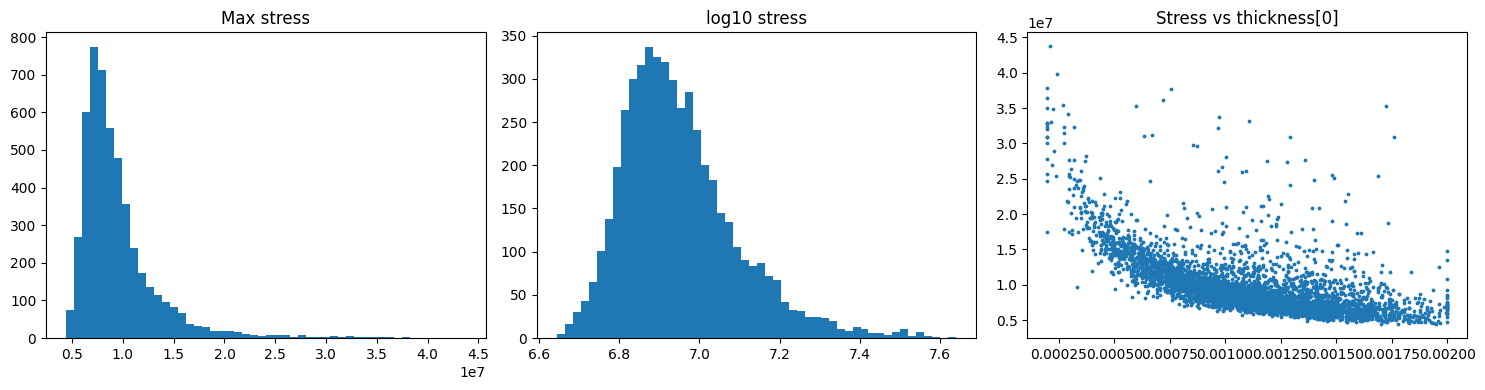

In [2]:
tr, tmp = train_test_split(np.arange(len(y)), test_size=.30, random_state=SEED)
va, te = train_test_split(tmp, test_size=.50, random_state=SEED)
print(len(tr), len(va), len(te))
F = np.concatenate([1/X, np.log(X)], 1); keep = F[tr].std(0) > 1e-9
mu, sd = F[tr][:, keep].mean(0), F[tr][:, keep].std(0)
Fs = ((F[:, keep] - mu) / sd).astype(np.float32)
ly = np.log(y); ym, ys = ly[tr].mean(), ly[tr].std(); yn = ((ly - ym) / ys).astype(np.float32)
p10, p25, p50 = np.percentile(y[tr], [10, 25, 50])
lab = lambda v: np.digitize(v, [p10, p25, p50], right=True)
cls = lab(y); class_names = ['0-10%', '11-25%', '26-50%', '51-100%']
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(y, 50); ax[0].set_title('Max stress'); ax[1].hist(np.log10(y), 50); ax[1].set_title('log10 stress')
ax[2].scatter(X[:, 0], y, s=3); ax[2].set_title('Stress vs thickness[0]'); plt.tight_layout(); plt.show()

In [3]:
T = torch.tensor
class DNN(nn.Module):
    def __init__(s, i, out=1, h=512, p=0.1, nb=3):
        super().__init__()
        s.i = nn.Linear(i, h)
        s.b = nn.ModuleList([nn.Sequential(nn.LayerNorm(h), nn.Linear(h, h), nn.GELU(), nn.Dropout(p), nn.Linear(h, h)) for _ in range(nb)])
        s.o = nn.Sequential(nn.LayerNorm(h), nn.Linear(h, out)); s.out = out
    def forward(s, x):
        x = s.i(x)
        for b in s.b: x = x + b(x)
        o = s.o(x); return o.squeeze(1) if s.out == 1 else o

def fit(seed, train_idx=tr, epochs=150, task='reg', verbose=False):
    torch.manual_seed(seed)
    m = DNN(Fs.shape[1], 1 if task == 'reg' else 4)
    opt = torch.optim.AdamW(m.parameters(), 1e-3, weight_decay=1e-2)
    nbt = (len(train_idx) + 63) // 64
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, 2e-3, total_steps=epochs * nbt)
    if task == 'reg':
        tgt = T(yn); crit = lambda o, t: nn.functional.smooth_l1_loss(o, t, beta=.5); vcrit = nn.functional.mse_loss
    else:
        tgt = T(cls); w = T(compute_class_weight('balanced', classes=np.arange(4), y=cls[train_idx]), dtype=torch.float32)
        crit = nn.CrossEntropyLoss(weight=w); vcrit = crit
    Xt, Xv = T(Fs[train_idx]), T(Fs[va]); yt, yv = tgt[train_idx], tgt[va]
    best = (9e9, None); hist = []
    for e in range(epochs):
        m.train(); perm = torch.randperm(len(train_idx)); L = 0
        for i in range(0, len(perm), 64):
            b = perm[i:i+64]; opt.zero_grad()
            l = crit(m(Xt[b] + 0.02*torch.randn(len(b), Xt.shape[1])), yt[b]); l.backward(); opt.step(); sch.step(); L += l.item()*len(b)
        m.eval()
        with torch.no_grad(): v = vcrit(m(Xv), yv).item()
        hist.append((L/len(perm), v))
        if v < best[0]: best = (v, {k: t.clone() for k, t in m.state_dict().items()})
        if verbose and (e+1) % 25 == 0: print(f'epoch {e+1} train {L/len(perm):.4f} val {v:.4f}')
    m.load_state_dict(best[1]); return m, hist

def pred_reg(m, ix):
    m.eval()
    with torch.no_grad(): return np.exp(m(T(Fs[ix])).numpy()*ys + ym)

## 1. Regression DNN (5-seed ensemble)

In [4]:
models, H = [], []
for s in range(5):
    m, h = fit(s, verbose=(s == 0)); models.append(m); H.append(h)
    print('seed', s, 'test R2', round(r2_score(y[te], pred_reg(m, te)), 4))
torch.save([m.state_dict() for m in models], 'outputs/dnn_ensemble.pth')

epoch 25 train 0.0313 val 0.1062
epoch 50 train 0.0112 val 0.0695
epoch 75 train 0.0048 val 0.0655
epoch 100 train 0.0019 val 0.0595
epoch 125 train 0.0007 val 0.0581
epoch 150 train 0.0004 val 0.0574
seed 0 test R2 0.9449
seed 1 test R2 0.9434
seed 2 test R2 0.9431
seed 3 test R2 0.9417
seed 4 test R2 0.9435


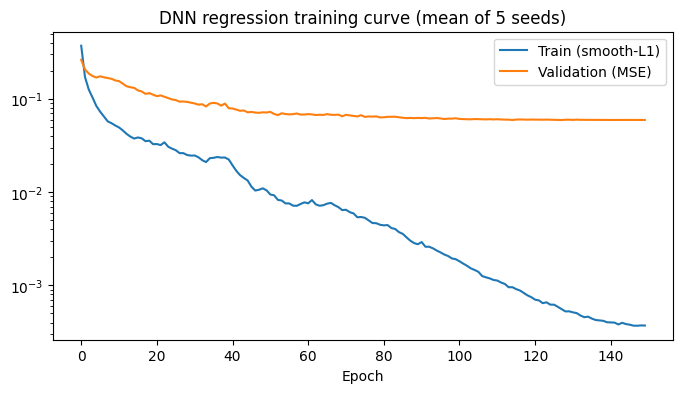

R2 0.9456 | RMSE 861,257 | MAE 563,385


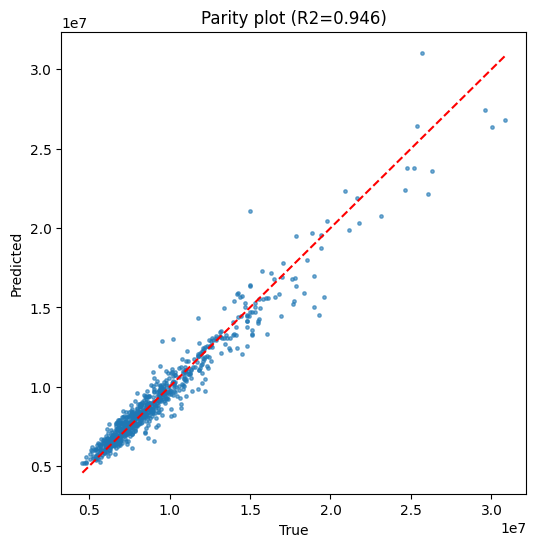

In [5]:
H = np.array(H).mean(0)
plt.figure(figsize=(8, 4)); plt.plot(H[:, 0], label='Train (smooth-L1)'); plt.plot(H[:, 1], label='Validation (MSE)')
plt.yscale('log'); plt.xlabel('Epoch'); plt.legend(); plt.title('DNN regression training curve (mean of 5 seeds)'); plt.show()
p = np.mean([pred_reg(m, te) for m in models], 0)
r2 = r2_score(y[te], p); rmse = mean_squared_error(y[te], p)**.5; mae = mean_absolute_error(y[te], p)
print(f'R2 {r2:.4f} | RMSE {rmse:,.0f} | MAE {mae:,.0f}')
plt.figure(figsize=(6, 6)); plt.scatter(y[te], p, s=6, alpha=.6)
lim = [y[te].min(), y[te].max()]; plt.plot(lim, lim, 'r--'); plt.xlabel('True'); plt.ylabel('Predicted'); plt.title(f'Parity plot (R2={r2:.3f})'); plt.show()

## 2. Regression -> bin vs. direct classification (both DNN)

Regression -> bin accuracy: 0.7827
              precision    recall  f1-score   support

       0-10%       0.87      0.57      0.69        81
      11-25%       0.57      0.61      0.59       122
      26-50%       0.66      0.74      0.70       192
     51-100%       0.92      0.92      0.92       355

    accuracy                           0.78       750
   macro avg       0.76      0.71      0.72       750
weighted avg       0.79      0.78      0.78       750



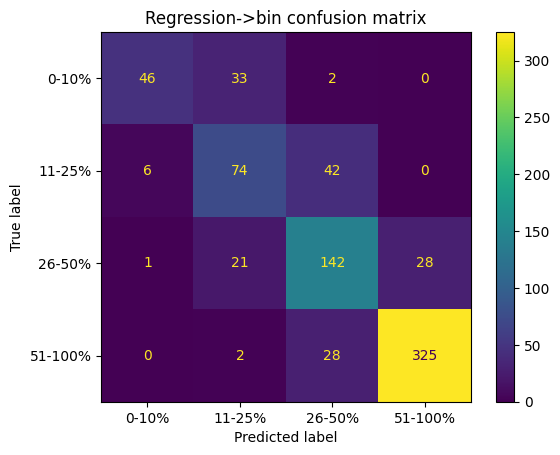

Direct classification DNN accuracy: 0.6253
              precision    recall  f1-score   support

       0-10%       0.51      0.53      0.52        81
      11-25%       0.33      0.37      0.35       122
      26-50%       0.47      0.47      0.47       192
     51-100%       0.87      0.82      0.84       355

    accuracy                           0.63       750
   macro avg       0.54      0.55      0.55       750
weighted avg       0.64      0.63      0.63       750



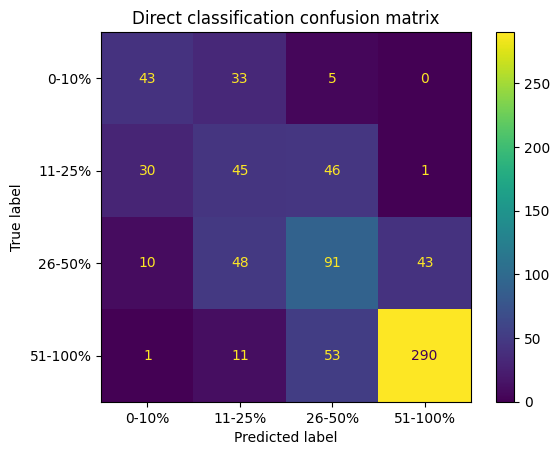

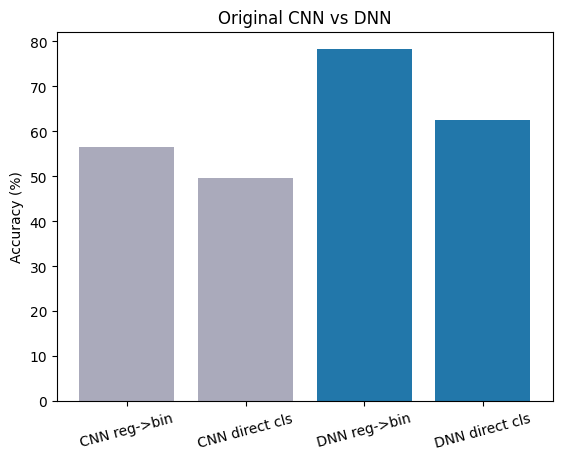

In [6]:
acc_reg = accuracy_score(cls[te], lab(p)); print('Regression -> bin accuracy:', round(acc_reg, 4))
print(classification_report(cls[te], lab(p), target_names=class_names))
ConfusionMatrixDisplay(confusion_matrix(cls[te], lab(p)), display_labels=class_names).plot(); plt.title('Regression->bin confusion matrix'); plt.show()
mc, hc = fit(0, epochs=100, task='cls')
mc.eval()
with torch.no_grad(): pc = mc(T(Fs[te])).argmax(1).numpy()
acc_cls = accuracy_score(cls[te], pc); print('Direct classification DNN accuracy:', round(acc_cls, 4))
print(classification_report(cls[te], pc, target_names=class_names))
ConfusionMatrixDisplay(confusion_matrix(cls[te], pc), display_labels=class_names).plot(); plt.title('Direct classification confusion matrix'); plt.show()
plt.bar(['CNN reg->bin', 'CNN direct cls', 'DNN reg->bin', 'DNN direct cls'], [56.5, 49.6, acc_reg*100, acc_cls*100], color=['#aab', '#aab', '#27a', '#27a'])
plt.ylabel('Accuracy (%)'); plt.xticks(rotation=15); plt.title('Original CNN vs DNN'); plt.show()

## 3. Measured data efficiency (replaces the hard-coded curve)
Single model per point, 80 epochs, evaluated on the same test set.

500 57.2 39.6
800 64.3 38.1
1500 68.5 48.9
2200 72.4 55.6
2800 76.5 60.5
3500 78.3 62.3


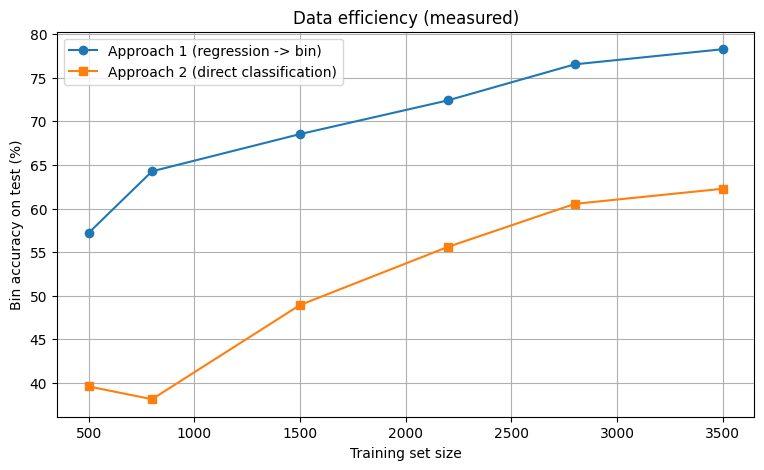

In [7]:
sizes = [500, 800, 1500, 2200, 2800, 3500]; ar, ac = [], []
rng = np.random.RandomState(0)
for n in sizes:
    sub = rng.choice(tr, n, replace=False)
    m1, _ = fit(0, sub, epochs=80); ar.append(accuracy_score(cls[te], lab(pred_reg(m1, te)))*100)
    m2, _ = fit(0, sub, epochs=80, task='cls'); m2.eval()
    with torch.no_grad(): ac.append(accuracy_score(cls[te], m2(T(Fs[te])).argmax(1).numpy())*100)
    print(n, round(ar[-1], 1), round(ac[-1], 1))
plt.figure(figsize=(9, 5)); plt.plot(sizes, ar, 'o-', label='Approach 1 (regression -> bin)'); plt.plot(sizes, ac, 's-', label='Approach 2 (direct classification)')
plt.xlabel('Training set size'); plt.ylabel('Bin accuracy on test (%)'); plt.grid(True); plt.legend(); plt.title('Data efficiency (measured)'); plt.show()

In [8]:
print(f'FINAL  R2={r2:.4f}  RMSE={rmse:,.0f}  MAE={mae:,.0f}  reg->bin acc={acc_reg:.4f}  direct cls acc={acc_cls:.4f}')

FINAL  R2=0.9456  RMSE=861,257  MAE=563,385  reg->bin acc=0.7827  direct cls acc=0.6253
